# Transformers, TP 4 : assembler et entraîner le mini-Transformer

Ce TP rassemble tout ce qui a été construit avant : la préparation des données du TP 1, l'attention du TP 2, la LayerNorm et le MLP du TP 3. On en fait un petit modèle de langage de caractères, on l'entraîne sur *Tiny Shakespeare*, on suit les losses de train et de validation, puis on génère du texte.

Ordre des étapes : données, tête d'attention, multi-têtes, bloc résiduel, modèle complet (embeddings, logits, loss, génération), évaluation et entraînement, génération finale, puis quelques expériences sur le contexte, le nombre de têtes et le dropout.

Le paramètre MODE_RAPIDE (cellule des hyperparamètres) sert à tester le code en quelques secondes avec 80 itérations. Pour le rendu, il vaut False : on fait alors les 5 000 itérations du sujet. Sur Colab, un GPU T4 accélère nettement l'entraînement, mais le modèle reste assez petit pour tourner sur CPU en quelques minutes.

## 0. Données et hyperparamètres

Même corpus, même tokenisation caractère par caractère et même découpage 90 / 10 que dans le TP 1.

In [1]:
import math
from pathlib import Path
from urllib.request import urlretrieve

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

_ = torch.manual_seed(1337)
print(f"PyTorch {torch.__version__} | GPU : {torch.cuda.is_available()}")

PyTorch 2.9.1+cpu | GPU : False


In [2]:
URL_CORPUS = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
fichier = Path("input.txt")
if not fichier.exists():
    urlretrieve(URL_CORPUS, fichier)
corpus = fichier.read_text(encoding="utf-8")

vocab = sorted(set(corpus))
vocab_size = len(vocab)
char_to_id = {c: i for i, c in enumerate(vocab)}
id_to_char = {i: c for c, i in char_to_id.items()}


def encode(texte):
    return [char_to_id[c] for c in texte]


def decode(ids):
    return "".join(id_to_char[int(i)] for i in ids)


data = torch.tensor(encode(corpus), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]

assert decode(encode(corpus[:40])) == corpus[:40]
print(f"{len(corpus):,} caractères, vocabulaire de {vocab_size} symboles")
print(f"train : {len(train_data):,} tokens | validation : {len(val_data):,} tokens")

1,115,394 caractères, vocabulaire de 65 symboles
train : 1,003,854 tokens | validation : 111,540 tokens


block_size fixe la longueur maximale du contexte. Les autres valeurs sont celles du sujet ; le mode rapide ne change que le nombre d'itérations et de batchs d'évaluation.

In [3]:
MODE_RAPIDE = False   # True : test du code en quelques secondes ; False : les 5 000 itérations du sujet

batch_size = 16
block_size = 32
max_iters = 80 if MODE_RAPIDE else 5000
eval_interval = 20 if MODE_RAPIDE else 100
eval_iters = 10 if MODE_RAPIDE else 200
learning_rate = 1e-3
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0
device = "cuda" if torch.cuda.is_available() else "cpu"

assert n_embd % n_head == 0
print(f"device : {device}")
print(f"taille d'une tête : {n_embd // n_head}")
print(f"positions prédites par batch : {batch_size} x {block_size} = {batch_size * block_size}")
print(f"itérations : {max_iters} | batchs par évaluation : {eval_iters}")

device : cpu
taille d'une tête : 16
positions prédites par batch : 16 x 32 = 512
itérations : 5000 | batchs par évaluation : 200


In [4]:
def get_batch(split, context_size=None, n=None):
    """(x, y) de forme (n, context_size), y décalé d'un cran ; par défaut (batch_size, block_size)."""
    source = train_data if split == "train" else val_data
    T = context_size or block_size
    B = n or batch_size
    departs = torch.randint(len(source) - T, (B,))
    x = torch.stack([source[i:i + T] for i in departs])
    y = torch.stack([source[i + 1:i + T + 1] for i in departs])
    return x.to(device), y.to(device)


xb, yb = get_batch("train")
assert torch.equal(xb[:, 1:], yb[:, :-1])   # y est bien x décalé d'un cran
print("x :", tuple(xb.shape), "| y :", tuple(yb.shape))

x : (16, 32) | y : (16, 32)


### Questions

*Dimension d'une tête ?*

64 / 4 = 16.

*Taille d'un batch ?*

16 séquences de 32 caractères, soit B × T = 512 positions à prédire à chaque pas.

*Que réduire sur CPU ?*

D'abord max_iters et eval_iters, pour vérifier que tout s'exécute (c'est le rôle de MODE_RAPIDE), puis éventuellement batch_size. Pour les résultats finaux, on garde la configuration du sujet afin que l'expérience reste comparable.

## 1. Une tête d'attention causale

C'est la tête du TP 2, rangée dans un module. La requête du token courant est comparée aux clés des tokens visibles ; le masque triangulaire cache le futur ; le softmax donne les poids qui pondèrent les valeurs.

In [5]:
class Head(nn.Module):
    """Tête d'attention causale : (B, T, n_embd) -> (B, T, head_size)."""

    def __init__(self, head_size, context_size=block_size, drop=dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(context_size, context_size)))
        self.dropout = nn.Dropout(drop)

    def poids(self, x):
        """Matrice d'attention (B, T, T), utile aussi pour les vérifications."""
        T = x.shape[1]
        q, k = self.query(x), self.key(x)                     # (B, T, d_h)
        scores = q @ k.transpose(-2, -1) * k.size(-1) ** -0.5   # (B, T, T), divisé par sqrt(d_h)
        scores = scores.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        return F.softmax(scores, dim=-1)                       # chaque ligne somme à 1

    def forward(self, x):
        wei = self.dropout(self.poids(x))
        return wei @ self.value(x)                             # (B, T, d_h)

Vérifications sans entraînement : les formes, la somme des lignes, le masque, et surtout le fait que le futur n'influence jamais le passé. Pour ce dernier point, on modifie fortement les tokens 5 à 7 et on contrôle que les sorties des positions 0 à 4 ne bougent pas.

In [6]:
torch.manual_seed(0)
tete = Head(head_size=16).eval()   # eval() : pas de dropout pendant le test
x_test = torch.randn(2, 8, n_embd)

with torch.no_grad():
    wei = tete.poids(x_test)
    sortie = tete(x_test)
    x_futur = x_test.clone()
    x_futur[:, 5:] += 100
    sortie_futur = tete(x_futur)

verifs = {
    "poids de forme (2, 8, 8)": wei.shape == (2, 8, 8),
    "sortie de forme (2, 8, 16)": sortie.shape == (2, 8, 16),
    "chaque ligne somme à 1": torch.allclose(wei.sum(-1), torch.ones(2, 8), atol=1e-6),
    "aucun poids au-dessus de la diagonale": torch.count_nonzero(torch.triu(wei, diagonal=1)).item() == 0,
    "le futur ne change pas les positions 0-4": torch.allclose(sortie[:, :5], sortie_futur[:, :5], atol=1e-5),
}
for nom, ok in verifs.items():
    print(f"[{'ok' if ok else 'ÉCHEC'}] {nom}")
assert all(verifs.values())

print("\nmatrice d'attention du 1er exemple :")
print(wei[0].round(decimals=3))

[ok] poids de forme (2, 8, 8)
[ok] sortie de forme (2, 8, 16)
[ok] chaque ligne somme à 1
[ok] aucun poids au-dessus de la diagonale
[ok] le futur ne change pas les positions 0-4

matrice d'attention du 1er exemple :


tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4310, 0.5690, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2170, 0.4270, 0.3560, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2350, 0.1740, 0.3270, 0.2630, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1540, 0.1820, 0.1300, 0.2380, 0.2950, 0.0000, 0.0000, 0.0000],
        [0.1610, 0.1190, 0.2070, 0.1330, 0.1360, 0.2430, 0.0000, 0.0000],
        [0.1270, 0.1630, 0.1650, 0.1110, 0.0990, 0.1780, 0.1580, 0.0000],
        [0.1570, 0.0940, 0.0830, 0.0790, 0.1870, 0.1930, 0.0620, 0.1460]])


### Questions

*Pourquoi diviser par k.size(-1) et pas par C ?*

Le produit scalaire compare des vecteurs de la tête, de dimension d_h = 16, et pas les embeddings d'entrée de dimension 64. C'est leur variance qui grandit avec d_h, donc on divise par √16.

*Pourquoi tril[:T, :T] ?*

Le masque est créé pour la longueur maximale block_size, mais le modèle reçoit parfois des séquences plus courtes, en particulier au début de la génération. On découpe donc le coin du masque qui correspond à la longueur réelle.

*Formes.*

q, k et v : (B, T, d_h). Poids : (B, T, T). Sortie : (B, T, d_h).

## 2. Plusieurs têtes en parallèle

Chaque tête produit 16 dimensions ; on les met bout à bout puis une projection linéaire les recombine en 64 dimensions.

In [7]:
class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size, context_size=block_size, drop=dropout):
        super().__init__()
        assert num_heads * head_size == n_embd
        self.heads = nn.ModuleList([Head(head_size, context_size, drop) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(drop)

    def forward(self, x):
        concat = torch.cat([h(x) for h in self.heads], dim=-1)   # (B, T, num_heads * head_size)
        return self.dropout(self.proj(concat))


mha = MultiHeadAttention(num_heads=4, head_size=16)
print("4 têtes de 16 dimensions :", tuple(mha(torch.randn(2, 8, n_embd)).shape))

4 têtes de 16 dimensions : (2, 8, 64)


### Questions

*Pourquoi concaténer sur dim=-1 ?*

On veut mettre côte à côte les features des quatre têtes pour chaque position, sans toucher à l'axe du temps : 4 × 16 = 64.

*Pourquoi n_embd doit-il être divisible par n_head ?*

Pour découper les 64 dimensions en têtes de même taille (16 chacune) et retrouver exactement 64 dimensions après la concaténation.

*À quoi sert la projection ?*

Les têtes travaillent chacune de leur côté. La couche proj mélange linéairement leurs résultats pour produire une seule représentation de taille 64.

## 3. Le bloc : attention, MLP, LayerNorm et résiduels

On reprend le MLP du TP 3 (avec un dropout en sortie) et on l'assemble avec l'attention dans un bloc pré-norm.

In [8]:
class FeedForward(nn.Module):
    """MLP appliqué à chaque token séparément : C -> 4C -> C."""

    def __init__(self, dim, drop=dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.ReLU(),
            nn.Linear(4 * dim, dim),
            nn.Dropout(drop),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Bloc pré-norm : x + attention(LN(x)), puis x + MLP(LN(x))."""

    def __init__(self, dim, num_heads, context_size=block_size, drop=dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim)
        self.sa = MultiHeadAttention(num_heads, dim // num_heads, context_size, drop)
        self.ln2 = nn.LayerNorm(dim)
        self.ffwd = FeedForward(dim, drop)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # communication entre positions
        x = x + self.ffwd(self.ln2(x))   # calcul token par token
        return x


print("bloc :", tuple(Block(n_embd, n_head)(torch.randn(2, 8, n_embd)).shape))

bloc : (2, 8, 64)


### Questions

*Dans quel ordre ?*

LayerNorm, puis la sous-couche (attention ou MLP), puis l'addition avec l'entrée. C'est l'organisation pré-norm.

*Qui fait communiquer les tokens ?*

L'attention : c'est elle qui va chercher de l'information dans les positions précédentes.

*Qui fait le calcul individuel ?*

Le MLP, qui transforme les features de chaque position sans accès aux autres tokens.

*Rôle du résiduel ?*

Avec x + delta, chaque sous-couche ajoute une correction au lieu de tout remplacer. Le signal et le gradient gardent un chemin direct à travers les blocs, ce qui facilite l'optimisation, et la forme reste (B, T, 64).

## 4. Le modèle complet

token_embedding_table encode le caractère, position_embedding_table encode sa position, les blocs mélangent le contexte et transforment chaque token, puis lm_head donne un score pour chaque caractère possible. La classe garde le nom BigramLanguageModel du TP 1 pour suivre l'énoncé, même si ce n'est plus un bigramme.

In [9]:
class BigramLanguageModel(nn.Module):

    def __init__(self, context_size=block_size, num_heads=n_head, n_blocks=n_layer, drop=dropout):
        super().__init__()
        self.context_size = context_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(context_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, num_heads, context_size, drop) for _ in range(n_blocks)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.context_size:
            raise ValueError(f"contexte de {T} tokens, maximum {self.context_size}")
        tok = self.token_embedding_table(idx)                                  # (B, T, 64)
        pos = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, 64)
        x = self.blocks(tok + pos)                                             # broadcasting -> (B, T, 64)
        logits = self.lm_head(self.ln_f(x))                                    # (B, T, vocab_size)
        if targets is None:
            return logits, None
        logits = logits.reshape(B * T, vocab_size)
        loss = F.cross_entropy(logits, targets.reshape(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            fenetre = idx[:, -self.context_size:]       # on ne garde que les derniers block_size tokens
            logits, _ = self(fenetre)
            probs = F.softmax(logits[:, -1, :], dim=-1)  # dernière position seulement
            idx = torch.cat((idx, torch.multinomial(probs, num_samples=1)), dim=1)
        return idx

Contrôles avant tout entraînement : sans cible, les logits gardent la forme (B, T, vocab_size) ; avec cibles, la loss porte sur les B × T positions aplaties.

In [10]:
model = BigramLanguageModel().to(device)
print(f"paramètres entraînables : {sum(p.numel() for p in model.parameters()):,}")

xb, yb = get_batch("train")
logits_gen, pas_de_loss = model(xb)
logits_train, loss_init = model(xb, yb)
assert logits_gen.shape == (batch_size, block_size, vocab_size)
assert logits_train.shape == (batch_size * block_size, vocab_size)
assert pas_de_loss is None and torch.isfinite(loss_init)

print("logits sans cible :", tuple(logits_gen.shape))
print("logits avec cible :", tuple(logits_train.shape))
print(f"loss initiale : {loss_init.item():.4f}  (uniforme : ln({vocab_size}) = {math.log(vocab_size):.4f})")

paramètres entraînables : 209,729
logits sans cible : (16, 32, 65)
logits avec cible : (512, 65)
loss initiale : 4.3755  (uniforme : ln(65) = 4.1744)


### Questions

*Tailles des matrices.*

Embedding des tokens : (V, 64). Embedding des positions : (32, 64). lm_head : une projection de 64 vers V, plus un biais de taille V.

*Pourquoi une lm_head séparée ?*

Dans le bigramme du TP 1, la table donnait directement les logits. Ici, chaque caractère passe d'abord par un espace de 64 dimensions où il est mis en contexte par les blocs ; il faut ensuite une couche pour revenir de ces 64 dimensions vers V logits.

*Broadcasting.*

(B, T, 64) + (T, 64) : le même vecteur de position est ajouté à toutes les séquences du batch.

*Loss.*

La cross-entropy compare les B × T prédictions aux caractères suivants. L'aplatissement ne sert que pour le calcul de la loss.

*@torch.no_grad().*

Pendant la génération, on ne construit pas de graphe de gradients, ce qui économise mémoire et temps.

*torch.multinomial.*

On tire le caractère suivant selon la distribution prédite. Un argmax choisirait toujours le plus probable et produirait vite des boucles répétitives.

In [11]:
debut = torch.zeros((1, 1), dtype=torch.long, device=device)
model.eval()
torch.manual_seed(2026)
texte_avant = decode(model.generate(debut, max_new_tokens=250)[0].tolist())
model.train()
print("Génération avant entraînement :\n")
print(texte_avant)

Génération avant entraînement :


OF3QOyrGlWG3eO
wMZ':ZALS
lzJJzF-HhH.fl TgqUELgYR-LSHHipyeg'cykNL
dUpzTPzkaYLVzStKzwAvqrIqy
aeawHnMbLIw?wFYqyRY-
-lBy3Gzu,w'Bm,yEF&;vKGMZzLr'InUvCJHR.lLX$
i.U
MlwqNNVxVVqJuL&HkbwC:GoLEhcaBMx$H'IDHn,IX,pywlR EeCrUazdaAX3flTHxa.VIYylwN3Y
tdLwvatkmzGMFKf


## 5. Mesurer la loss, puis entraîner

estimate_loss moyenne la loss sur eval_iters batchs en train et en validation. Elle passe le modèle en mode évaluation le temps de la mesure, puis remet le mode dans lequel il était.

In [12]:
@torch.no_grad()
def estimate_loss(net, n_batchs=None, context_size=None):
    n_batchs = n_batchs or eval_iters
    T = context_size or net.context_size
    mode_initial = net.training
    net.eval()
    resultat = {}
    for split in ("train", "val"):
        losses = [net(*get_batch(split, context_size=T))[1].item() for _ in range(n_batchs)]
        resultat[split] = sum(losses) / len(losses)
    net.train(mode_initial)
    return resultat


depart = estimate_loss(model)
print(f"loss estimée avant entraînement : train {depart['train']:.4f} | val {depart['val']:.4f}")

loss estimée avant entraînement : train 4.3365 | val 4.3484


In [13]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
historique = []

for it in range(max_iters + 1):
    if it % eval_interval == 0 or it == max_iters:
        l = estimate_loss(model)
        historique.append((it, l["train"], l["val"]))
        if it % (eval_interval * 10) == 0 or it == max_iters or MODE_RAPIDE:
            print(f"itération {it:>5} | train {l['train']:.4f} | val {l['val']:.4f}")
    if it == max_iters:
        break
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

itération     0 | train 4.3350 | val 4.3464


itération  1000 | train 2.0720 | val 2.1046


itération  2000 | train 1.8641 | val 1.9632


itération  3000 | train 1.7464 | val 1.8999


itération  4000 | train 1.7035 | val 1.8680


itération  5000 | train 1.6656 | val 1.8081


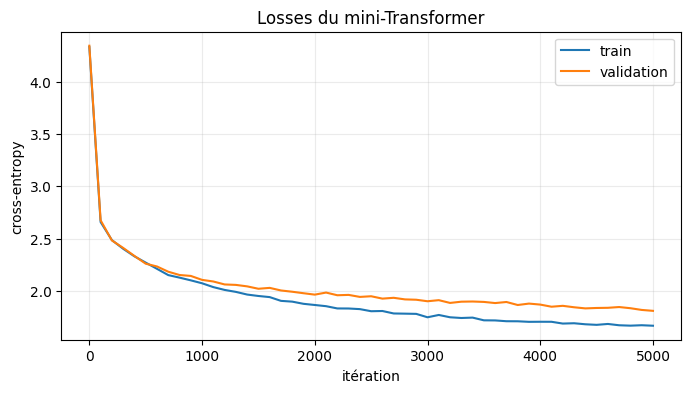

train : 4.335 -> 1.666
val   : 4.346 -> 1.808
écart final val - train : +0.142


In [14]:
iters, l_train, l_val = zip(*historique)

plt.figure(figsize=(8, 4))
plt.plot(iters, l_train, label="train")
plt.plot(iters, l_val, label="validation")
plt.xlabel("itération"); plt.ylabel("cross-entropy")
plt.title("Losses du mini-Transformer")
plt.legend(); plt.grid(alpha=0.25)
plt.show()

ecart = l_val[-1] - l_train[-1]
print(f"train : {l_train[0]:.3f} -> {l_train[-1]:.3f}")
print(f"val   : {l_val[0]:.3f} -> {l_val[-1]:.3f}")
print(f"écart final val - train : {ecart:+.3f}")

### Questions

*Pourquoi model.eval() puis model.train() ?*

Pendant la mesure, certaines couches doivent se comporter comme à l'inférence, en particulier le dropout, qui doit être coupé. Une fois la mesure faite, on remet le mode d'entraînement pour continuer l'optimisation.

*Et si la loss de train baisse alors que celle de validation remonte ?*

C'est le signe d'un surapprentissage : le modèle apprend le train par cœur au lieu de généraliser. On le repère en comparant les deux courbes ; on peut alors ajouter du dropout ou arrêter l'entraînement plus tôt.

*Ce qu'on observe ici.*

Les deux losses baissent nettement : de 4,34 à 1,67 en train et de 4,35 à 1,81 en validation après 5 000 itérations. La descente est rapide au début (2,07 en train dès 1 000 itérations) puis ralentit. La validation baisse encore à la fin, donc pas de surapprentissage au sens strict, mais l'écart avec le train se creuse doucement (+0,03 à 1 000 itérations, +0,14 à la fin) : le modèle commence à mieux connaître le train que le texte qu'il n'a jamais vu. Pour comparaison, le bigramme du TP 1 plafonnait autour de 4,0 après 1 000 pas.

## 6. Générer après l'entraînement

Même point de départ et même graine que pour la génération avant entraînement, mais 2 000 caractères cette fois.

In [15]:
model.eval()
torch.manual_seed(2026)
texte_apres = decode(model.generate(debut, max_new_tokens=2000)[0].tolist())

print("AVANT ENTRAÎNEMENT (250 caractères)\n")
print(texte_avant)
print("\n\nAPRÈS ENTRAÎNEMENT (2 000 caractères)\n")
print(texte_apres)

AVANT ENTRAÎNEMENT (250 caractères)


OF3QOyrGlWG3eO
wMZ':ZALS
lzJJzF-HhH.fl TgqUELgYR-LSHHipyeg'cykNL
dUpzTPzkaYLVzStKzwAvqrIqy
aeawHnMbLIw?wFYqyRY-
-lBy3Gzu,w'Bm,yEF&;vKGMZzLr'InUvCJHR.lLX$
i.U
MlwqNNVxVVqJuL&HkbwC:GoLEhcaBMx$H'IDHn,IX,pywlR EeCrUazdaAX3flTHxa.VIYylwN3Y
tdLwvatkmzGMFKf


APRÈS ENTRAÎNEMENT (2 000 caractères)


And a reliver swee's wear.
As this as trumple my freart enacy grod
Their abred these wout take he beens her soot
As if theism again, hark, 'I pridess.

DUKE VINCENTIO:
O, sell where have mong's contropy loness day and fromsing
Yelw wouth histiment of and Lanly hard with envoin minal:
She man thy queen, I'll upchion!
more there had cland men trusitimined dute it:
Not mold sk sown!
Romeo:
A saim, mest sair in live on affer bece belieng
Intiment ensel of those
Wall togain dussitimes and we'll ke and ber frown.

ISABY'lET:
That a can thinders burged soUl.

Host grive OF Courdshing.

WARWICK:
I'll dath; be with now; posion a
houmiive to to wich harg force! I,
And o'

### Avant / après

Avant entraînement, on obtient une suite de caractères tirés presque au hasard : majuscules, ponctuation et symboles mélangés, aucune structure.

Après entraînement, la forme d'une pièce de théâtre apparaît clairement : des noms de personnages en majuscules suivis de deux-points (DUKE VINCENTIO:, WARWICK:, CORIOLANUS:, Nurse:), des répliques coupées en vers qui commencent par une majuscule, une ponctuation plausible. Beaucoup de mots courts sont corrects (*with*, *thou*, *father*, *grace*, *peace*, *I'll*), mais les mots longs sont souvent inventés (*trusitimined*, *contropy*) et les phrases n'ont pas de sens. C'est ce qu'on attend d'un modèle de 210 000 paramètres qui ne voit que 32 caractères de contexte : il a appris l'orthographe locale et la mise en page, pas la langue.

## 7. Expériences : contexte, têtes, dropout

Le sujet propose de faire varier block_size (16 et 64), le nombre de têtes à embedding constant (1 contre 4), et le dropout (0,2). Chaque variante repart de poids aléatoires et s'entraîne avec le même petit budget de 60 pas ; le modèle principal n'est pas touché. Ce sont des comparaisons exploratoires, pas des résultats à 5 000 itérations.

In [16]:
def tester_variante(contexte=32, tetes=4, drop=0.0, pas=60):
    reseau = BigramLanguageModel(context_size=contexte, num_heads=tetes, n_blocks=n_layer, drop=drop).to(device)
    optim = torch.optim.AdamW(reseau.parameters(), lr=learning_rate)
    avant = estimate_loss(reseau, n_batchs=5)["val"]
    for _ in range(pas):
        _, l = reseau(*get_batch("train", context_size=contexte))
        optim.zero_grad(set_to_none=True)
        l.backward()
        optim.step()
    apres = estimate_loss(reseau, n_batchs=5)["val"]
    return {"T": contexte, "têtes": tetes, "dropout": drop,
            "paramètres": sum(p.numel() for p in reseau.parameters()),
            "val avant": round(avant, 3), "val après": round(apres, 3)}


variantes = [(16, 4, 0.0), (64, 4, 0.0), (32, 1, 0.0), (32, 4, 0.2)]
print(f"{'T':>3} {'têtes':>6} {'dropout':>8} {'paramètres':>11} {'val avant':>10} {'val après':>10}")
for i, (T, h, p) in enumerate(variantes):
    torch.manual_seed(1337 + i)
    r = tester_variante(T, h, p)
    print(f"{r['T']:>3} {r['têtes']:>6} {r['dropout']:>8} {r['paramètres']:>11,} {r['val avant']:>10} {r['val après']:>10}")

  T  têtes  dropout  paramètres  val avant  val après


 16      4      0.0     208,705      4.358      2.795


 64      4      0.0     211,777      4.343      2.809


 32      1      0.0     209,729       4.33      2.943


 32      4      0.2     209,729      4.415      2.824


### Lecture des expériences

Contexte 16 ou 64 : un contexte plus long donne accès à plus de caractères passés, au prix d'une attention plus coûteuse (en T²) et de quelques paramètres en plus pour les positions.

1 tête ou 4 têtes : avec n_embd = 64 fixé, une seule tête a 64 dimensions, quatre têtes en ont 16 chacune. Le nombre de paramètres est identique ; plusieurs têtes peuvent apprendre des façons différentes de pondérer le passé.

Dropout 0 ou 0,2 : le dropout régularise, ce qui peut aider quand train et validation s'écartent. Après 60 pas, le modèle est encore très loin de ce régime, donc on ne s'attend pas à un gain ici.

Dans nos résultats, la variante à une seule tête finit un peu plus haut (2,94 en validation) que les trois autres (entre 2,80 et 2,82).

Avec 60 pas, une seule graine et 5 batchs d'évaluation, les différences entre variantes restent de l'ordre du bruit. Pour conclure qu'une variante est meilleure, il faudrait répéter avec plusieurs graines et un budget d'entraînement plus long.

## Bilan des quatre TP

| Composant | TP | Rôle |
|---|---|---|
| BigramLanguageModel du TP 1 | 1 : bigramme | prédit le caractère suivant à partir du seul caractère courant |
| Head, MultiHeadAttention | 2 : auto-attention causale | donnent du contexte : chaque token consulte les positions passées et la sienne |
| nn.LayerNorm | 3 : normalisation | stabilise les features de chaque token sans mélanger les positions |
| FeedForward | 3 : MLP | transforme chaque token séparément, avec une non-linéarité |
| Block | 4 : blocs et résiduels | enchaîne communication entre positions, calcul par token et additions résiduelles |
| lm_head | 4 : sortie | produit les logits sur les caractères possibles |
| F.cross_entropy et loss.backward() | 4 : apprentissage | compare les logits aux cibles et propage les gradients dans tout le modèle |

*Quelle brique crée le contexte ?*

L'attention masquée, avec les poids softmax(QKᵀ/√d_h).

*Laquelle transforme un token ?*

Le MLP, position par position.

*Laquelle produit les logits ?*

lm_head, qui projette les 64 dimensions vers vocab_size scores.

*Où agit la loss ?*

Elle est calculée sur les B × T positions, et la rétropropagation ajuste tout : les embeddings, les projections d'attention, les LayerNorm, les MLP et lm_head.